In [5]:
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import ggcmpy
from scipy import constants
import ggcmpy.tracing
import pandas as pd
import pathlib

R_E = 6.371e6  # m



In [ ]:
# RUN = "sft8-20160920-1-3d-b"
# GGCM_DIR = pathlib.Path("~/ggcm").expanduser()
# ds = xr.open_mfdataset(f"{GGCM_DIR}/{RUN}/target/*.3df.004[6-9]*.bp")
ds = xr.open_dataset(f"{ggcmpy.sample_dir}/sample_jrrle.3df.001200")
ds

<xarray.Dataset> Size: 4MB
Dimensions:       (x: 64, y: 32, z: 32, time: 1)
Coordinates:
  * x             (x) float32 256B -30.0 -28.8 -27.61 ... 73.25 81.63 90.0
  * y             (y) float32 128B -50.0 -40.94 -33.05 ... 33.05 40.94 50.0
  * z             (z) float32 128B -50.0 -40.94 -33.05 ... 33.05 40.94 50.0
  * time          (time) datetime64[ns] 8B 1967-01-01T00:20:00.033000
Data variables: (12/16)
    bx            (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    by            (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    bz            (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    vx            (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    vy            (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    vz            (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    ...            ...
    xjy           (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    xjz           (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    xtra1         (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    xtra2         (x, y, z) float32 262kB dask.array<chunksize=(64, 32, 32), meta=np.ndarray>
    inttime       (time) int64 8B dask.array<chunksize=(1,), meta=np.ndarray>
    elapsed_time  (time) float64 8B dask.array<chunksize=(1,), meta=np.ndarray>
Attributes:
    run:      sample_jrrle

In [12]:
ds["xj"] = ds.ggcm.current_density()
xj_z = ds["xj"].isel(time=0).sel(z=0.0, method="nearest")
fig, ax = plt.subplots(figsize=(15, 5))
xj_z.plot(x="x", y="y", norm=mpl.colors.LogNorm(vmin=1e-4, vmax=1e-2), cmap="openggcm", ax=ax)
xj_z.plot.contour(x="x", y="y", levels=np.logspace(-4, -2, 5), colors="k", linewidths=0.5, ax=ax)
ax.set_aspect("equal")
ax.set_xlim(50, -20)
ax.set_ylim(-20, 20)

ValueError: Dimensions {'time'} do not exist. Expected one or more of ('x', 'y', 'z')

In [4]:
class TraceSimulation:
    def __init__(self, ds, q, m):
        self.ds = ds
        self.q = q
        self.m = m
        self._set_frame(0)

    def _set_frame(self, frame):
        self._frame = frame
        self.fields = ggcmpy.tracing.emfields.yee_cic_cxx(ggcmpy.tracing.emfields.prepare_yee_dataset(self.ds.isel(time=frame)))
        self.boris = ggcmpy.tracing.integrator.boris_cxx(self.fields, q=self.q, m=self.m, scale_B=1e-9, scale_E=1e-3, scale_r=R_E)

    def trace_one_frame(self, prts0, frame, t_final=None):
        self._set_frame(frame)
        if t_final is None:
            t_final = (self.ds.time[frame+1] - self.ds.time[0]) / np.timedelta64(1, 's')
        print("t_final", t_final)
    
        _, prts = self.boris.integrate(prts0, max_steps=100000,t_final=t_final, snapshot_on_equator_crossing=True)
        prts_gc = ggcmpy.tracing.to_guiding_center(prts, self.q, self.m, self.boris._fields, scale_B=1e-9, scale_E=1e-3, scale_r=R_E)

        return prts, prts_gc

trace_sim = TraceSimulation(ds, -constants.e, constants.m_e)

In [5]:
q, m = trace_sim.q, trace_sim.m
prts_array = []
for n, x in enumerate(np.linspace(-5.0, -6.0 , 2)):
    r0 = np.array([x, 0, 0])
    B_r0 = 1e-9 * trace_sim.fields.B(r0)

    E_kin = 10000.0 * 1e3 * constants.e  # 100 keV in J
    gamma = 1.0 + E_kin / (m * constants.c**2)
    v_e = constants.c * np.sqrt(1.0 - 1.0 / gamma**2)

    v0 = np.array([0.0, v_e / np.sqrt(2.0), v_e / np.sqrt(2.0)])  # [m/s]
    u0 = gamma * v0 / constants.c
    prts_array.append([n, 0.0, *r0, *u0])

prts0 = pd.DataFrame(
    prts_array, columns=["id", "time", "x", "y", "z", "ux", "uy", "uz"]
)

om_ce = np.abs(q) * np.linalg.norm(B_r0) / (gamma * m)  # gyrofrequency
r_ce = m * v_e / (q * np.linalg.norm(B_r0))  # gyroradius

t_final = 10.0 #50000 * 2 * np.pi / om_ce  # [s]
print(f"B={B_r0} om_ce={om_ce} r_ce={r_ce} t_final={t_final}")  # noqa: T201
prts0

B=[2.43626101e-08 8.90010008e-08 1.45538252e-07] om_ce=1473.4897025300447 r_ce=-9879.518587723658 t_final=10.0


,id,time,x,y,z,ux,uy,uz
0,0,0.0,-5.0,0.0,0.0,0.0,14.527643,14.527643
1,1,0.0,-6.0,0.0,0.0,0.0,14.527643,14.527643


In [6]:
dfs, dfs_gc = [], []
for frame in range(2):
    print("frame", frame)
    df, df_gc = trace_sim.trace_one_frame(prts0, frame=frame)
    dfs.append(df)
    dfs_gc.append(df_gc)


frame 0
t_final <xarray.DataArray 'time' ()> Size: 8B
array(120.00484506)
frame 1
t_final <xarray.DataArray 'time' ()> Size: 8B
array(240.00968986)


In [7]:
df = pd.concat(dfs, ignore_index=True)
df_gc = pd.concat(dfs_gc, ignore_index=True)

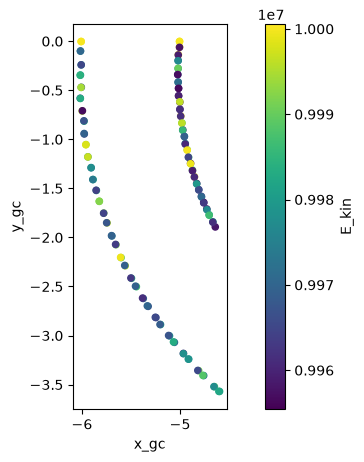

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
df_gc.iloc[::1].plot.scatter(x="x_gc", y="y_gc", c="E_kin", ax=ax)
# df.plot.scatter(x="x", y="y", marker="+", ax=ax)
ax.set_aspect("equal")

(-20.0, 20.0)

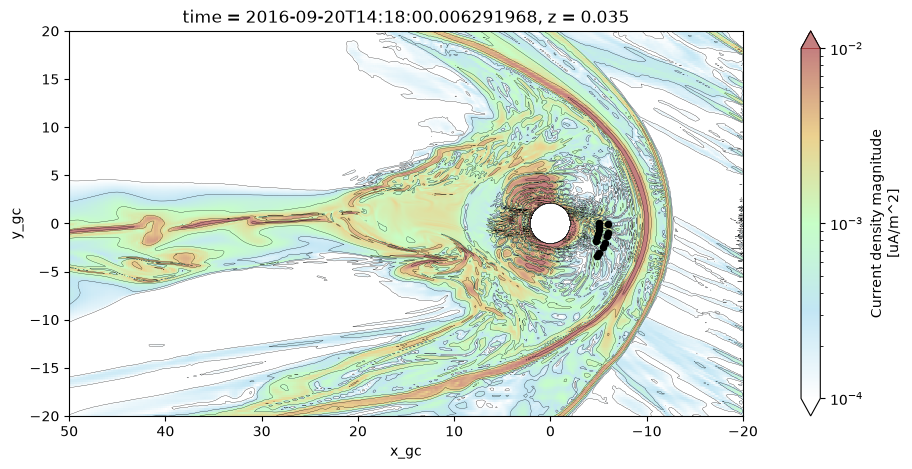

In [9]:
fig, ax = plt.subplots(figsize=(15, 5))
xj_z.plot(x="x", y="y", norm=mpl.colors.LogNorm(vmin=1e-4, vmax=1e-2), cmap="openggcm", alpha=0.5,ax=ax)
xj_z.plot.contour(x="x", y="y", levels=np.logspace(-4, -2, 5), colors="k", linewidths=0.2, ax=ax)
df_gc.iloc[::10].plot.scatter(x="x_gc", y="y_gc", marker="o", color="k", ax=ax)
ax.set_aspect("equal")
ax.set_xlim(50, -20)
ax.set_ylim(-20, 20)

In [10]:
xxx

NameError: name 'xxx' is not defined

In [ ]:
_, df = boris.integrate(prts0[prts0.id >= 0], t_final=t_final, dt_max_gyro=0.1, snapshot_interval_steps=None, snapshot_on_equator_crossing=True)
df_gc = to_gc(df, q, m, boris._fields)
# df[(-0.1 * R_E < df.z) & (df.z < 0.1 * R_E)].plot.scatter(x="x", y="y", c="time")
df_gc.plot.scatter(x="x_gc", y="y_gc", c="id")
df_gc

NameError: name 'boris' is not defined

In [ ]:
xxx

NameError: name 'xxx' is not defined

,id,time,x,y,z,ux,uy,uz
0,0,0.000000,-3.185500e+07,0.000000,0.000000e+00,0.000000,14.527643,14.527643
1,1,0.000000,-3.256289e+07,0.000000,0.000000e+00,0.000000,14.527643,14.527643
2,2,0.000000,-3.327078e+07,0.000000,0.000000e+00,0.000000,14.527643,14.527643
3,3,0.000000,-3.397867e+07,0.000000,0.000000e+00,0.000000,14.527643,14.527643
4,4,0.000000,-3.468656e+07,0.000000,0.000000e+00,0.000000,14.527643,14.527643
...,...,...,...,...,...,...,...,...
1065,5,0.102620,-2.719668e+07,260870.542102,1.186893e+07,8.433214,9.405130,-16.202754
1066,6,0.102822,-2.776880e+07,153282.383926,1.214442e+07,-1.863643,19.327580,6.713889
1067,7,0.102624,-2.828784e+07,92799.690194,1.226067e+07,-7.201001,-4.164295,18.785873
1068,8,0.102697,-2.888145e+07,95970.987482,1.251530e+07,-6.787396,3.746894,19.026215


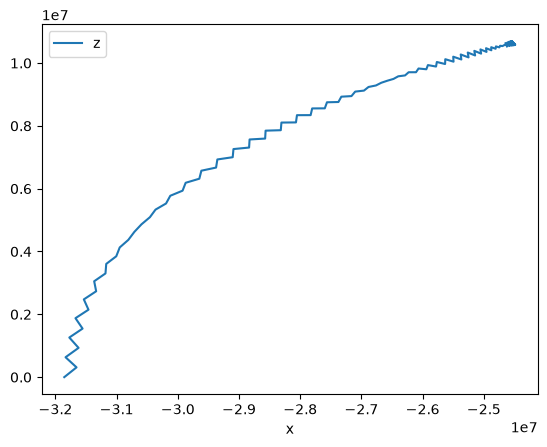

In [ ]:
df = boris.integrate(prts0, t_final=t_final, dt_max_gyro=0.1, snapshot_interval_steps=5)
df[df.id==0].plot(x="x", y="z")
df


In [ ]:
def trace_particles(prts0, t_final, dt):
    df = prts0
    dfs_split = [df]
    for t in np.arange(dt, t_final + dt, dt):
        df = boris.integrate(df, t_final=t, dt_max_gyro=0.1, snapshot_interval_steps=None)
        dfs_split.append(df)
        df = df.drop_duplicates(subset="id", keep="last")
    return pd.concat(dfs_split, ignore_index=True)

In [ ]:
df3 = trace_particles(prts0, t_final=10*t_final, dt=1.0)
df3_gc = to_gc(df3, q, m, boris._fields)

KeyError: 'z '

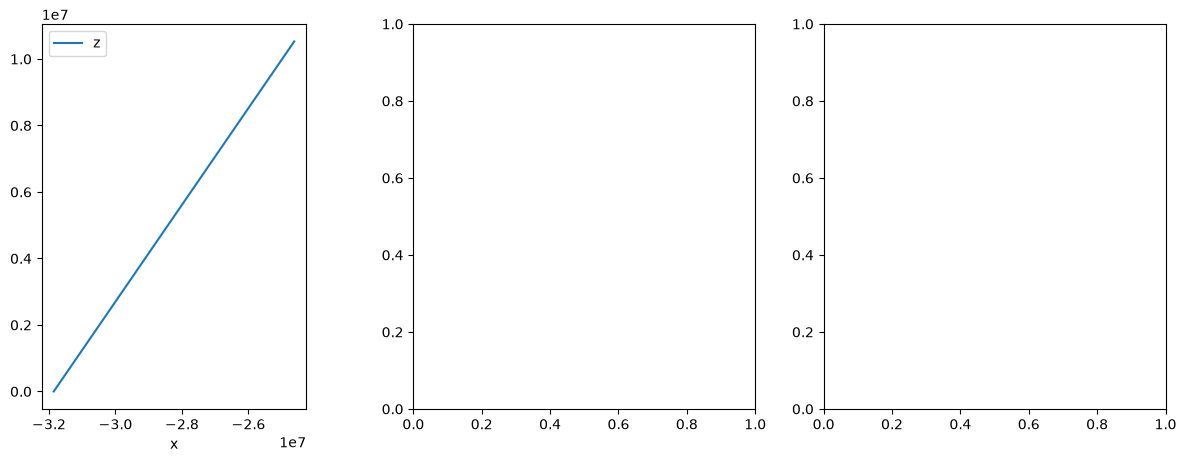

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
df[df.id==0].plot(x="x", y="z", ax=axs[0])
axs[0].set_aspect("equal")
df3[df3.id==0].plot.scatter(x="x", y="z ", c="time", ax=axs[1])
axs[1].set_aspect("equal")
df3_gc[df3_gc.id==0].plot.scatter(x="x_gc", y="z_gc", c="time", ax=axs[2])
axs[2].set_aspect("equal")

In [ ]:
def equator_crossings(fields, df_sparse):
    df_eq_list = []
    for _, row in df_sparse.iterrows():
        t0 = row["time"]
        r0 = row[["x_gc", "y_gc", "z_gc"]].values
        B0 = fields.B(r0)
        E_kin = (
            row["mu"] * np.linalg.norm(B0)
            + 0.5 * m * row["v_par"] ** 2
        ) / constants.e  # convert to eV

        df_field_line = field_line_equator(fields, t0, r0)
        df_field_line = df_field_line[-1:]
        if np.abs(df_field_line["z"].values[0]) > 1e3:
            continue
        df_field_line = df_field_line.rename(
            columns={"x": "x_gc", "y": "y_gc", "z": "z_gc"}
        )
        df_field_line["time"] = row["time"]
        df_field_line["mu"] = row["mu"]
        df_field_line["v_par"] = row["v_par"]
        df_field_line["E_kin"] = E_kin
        df_eq_list.append(df_field_line)

    df_eq = pd.concat(df_eq_list, ignore_index=True)
    df_eq["x_gc_RE"] = df_eq["x_gc"] / R_E
    df_eq["y_gc_RE"] = df_eq["y_gc"] / R_E
    return df_eq


In [ ]:
df4 = trace_particles(prts0, t_final=20*t_final, dt=0.01)
df4_gc = to_gc(df4, q, m, boris._fields)
df4_gc

,id,time,x_gc,y_gc,z_gc,v_par,mu
0,0.0,0.000000,-3.188503e+07,-1.596480e+04,1.596480e+04,19.636385,0.000005
1,1.0,0.000000,-3.259402e+07,-1.634752e+04,1.634752e+04,19.683450,0.000005
2,2.0,0.000000,-3.330325e+07,-1.672855e+04,1.672855e+04,19.721598,0.000006
3,3.0,0.000000,-3.401290e+07,-1.700401e+04,1.700401e+04,19.742024,0.000006
4,4.0,0.000000,-3.472290e+07,-1.734832e+04,1.734832e+04,19.754809,0.000006
...,...,...,...,...,...,...,...
34705,5.0,17.020214,-2.289459e+07,-2.206076e+07,1.564522e+07,19.794697,0.000006
34706,6.0,17.020019,-2.029768e+07,-2.798725e+07,4.720811e+06,-19.587868,0.000007
34707,7.0,17.020201,-2.152401e+07,-2.849455e+07,7.016687e+06,-19.860850,0.000006
34708,8.0,17.020029,-9.938569e+06,-2.297832e+06,1.691381e+07,11.536422,0.000007


In [ ]:
df_eq_test_gc = df4_gc[df4_gc.id<1]
df_eq = equator_crossings(boris._fields, df_eq_test_gc.iloc[::60])
# df_eq

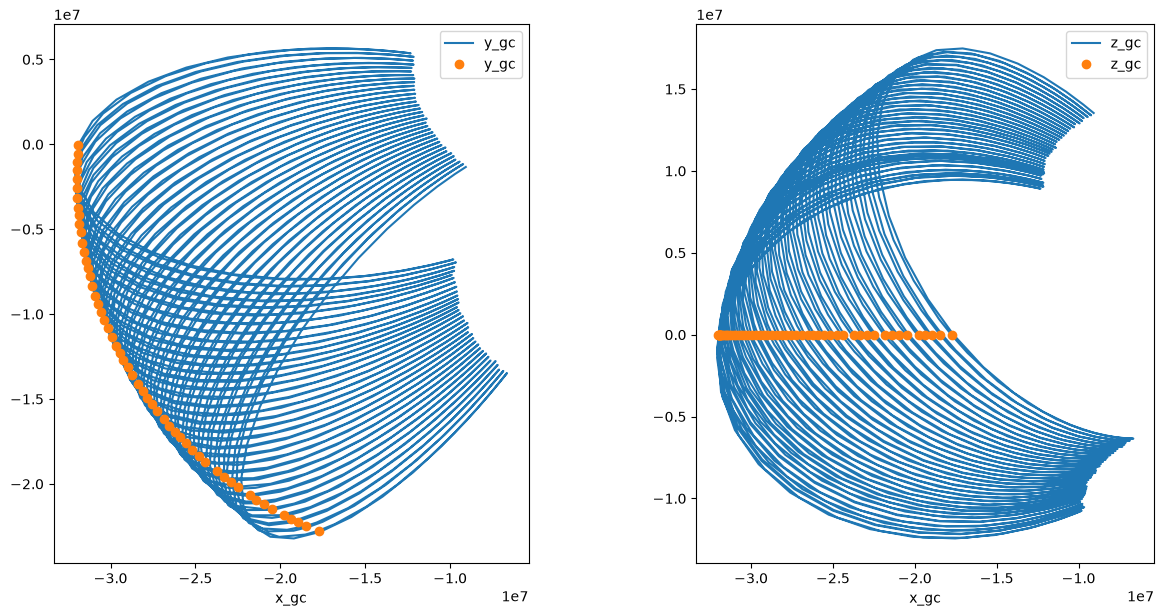

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
# for id in range(2):
    # df_eq_test_gc[df_eq_test_gc.id==id].plot(x="x_gc", y="y_gc", ax=axs[0], label=f"id={id}")
    # df_eq[df_eq.id==id].plot(x="x_gc", y="y_gc", style="o", ax=axs[0], label=f"id={id} eq")
    # df_eq_test_gc[df_eq_test_gc.id==id].plot(x="x_gc", y="z_gc", ax=axs[1], label=f"id={id}")
    # df_eq[df_eq.id==id].plot(x="x_gc", y="z_gc", style="o", ax=axs[1], label=f"id={id} eq")
df_eq_test_gc.plot(x="x_gc", y="y_gc", ax=axs[0])
df_eq.plot(x="x_gc", y="y_gc", style="o", ax=axs[0])
# df_eq.plot.scatter(x="x_gc", y="y_gc", c="time", s=100, ax=ax)
df_eq_test_gc.plot(x="x_gc", y="z_gc", ax=axs[1])
df_eq.plot(x="x_gc", y="z_gc", style="o", ax=axs[1])
axs[0].set_aspect("equal")
axs[1].set_aspect("equal")

In [ ]:
df_eq.iloc[-1]

time       1.677001e+01
x_gc      -1.770367e+07
y_gc      -2.279379e+07
z_gc       5.238689e-10
mu         5.958084e-06
v_par      1.396569e+00
E_kin      1.073492e+08
x_gc_RE   -2.778790e+00
y_gc_RE   -3.577741e+00
Name: 53, dtype: float64